<a href="https://colab.research.google.com/github/MrX9955/Kidney-Disease-MLOps/blob/main/notebooks/Experiment_1_Dataset_Creation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import os
import json
import hashlib

from datetime import datetime

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
folders = [
    "datasets/v1",
    "datasets/v2",
    "metadata",
    "screenshots"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


In [3]:

import numpy as np
import pandas as pd
import os

np.random.seed(42)

n = 1000

# Generate target classes
classes = [
    "No_Disease",
    "Low_Risk",
    "Moderate_Risk",
    "High_Risk",
    "Severe_Disease"
]

risk = np.random.choice(
    classes,
    size=n,
    p=[0.50, 0.20, 0.12, 0.10, 0.08]
)

# Risk-based numerical values
risk_level = pd.Series(risk).map({
    "No_Disease": 0,
    "Low_Risk": 1,
    "Moderate_Risk": 2,
    "High_Risk": 3,
    "Severe_Disease": 4
}).values

df = pd.DataFrame({
    "Age": np.random.randint(18, 85, n),
    "Blood_Pressure": np.random.normal(
        115 + risk_level * 8, 12, n
    ).round(2),
    "Blood_Glucose": np.random.normal(
        90 + risk_level * 25, 15, n
    ).round(2),
    "Creatinine": np.random.normal(
        0.8 + risk_level * 0.7, 0.3, n
    ).round(2),
    "Hemoglobin": np.random.normal(
        15 - risk_level * 1.5, 1.5, n
    ).round(2),
    "BMI": np.random.normal(24 + risk_level * 1.5, 4, n).round(2),
    "Urea": np.random.normal(
        25 + risk_level * 15, 8, n
    ).round(2),
    "Sodium": np.random.normal(
        140 - risk_level * 1.5, 3, n
    ).round(2),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Smoking": np.random.choice(["Yes", "No"], n),
    "Diabetes": np.random.choice(["Yes", "No"], n),
    "Hypertension": np.random.choice(["Yes", "No"], n),
    "Disease_Risk": risk
})

# Save Version 1
df.to_csv(
    "datasets/v1/kidney_disease_v1.csv",
    index=False
)

print("Version 1 dataset created successfully!")
print("Dataset Shape:", df.shape)
print(df.head())


Version 1 dataset created successfully!
Dataset Shape: (1000, 13)
   Age  Blood_Pressure  Blood_Glucose  Creatinine  Hemoglobin    BMI   Urea  \
0   64          107.50          73.45        0.92       17.02  20.85  32.16   
1   29          156.93         195.39        3.35        7.11  26.86  71.08   
2   79          130.92         125.18        1.90       14.96  34.20  53.42   
3   25          138.75         123.02        1.41       14.12  28.94  49.34   
4   38          128.39          74.44        1.21       16.55  22.99  29.01   

   Sodium  Gender Smoking Diabetes Hypertension    Disease_Risk  
0  141.67    Male     Yes      Yes           No      No_Disease  
1  133.73  Female      No       No          Yes  Severe_Disease  
2  137.26    Male      No       No          Yes   Moderate_Risk  
3  134.02  Female     Yes      Yes           No        Low_Risk  
4  141.19    Male     Yes      Yes           No      No_Disease  


In [4]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Disease_Risk"].value_counts())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             1000 non-null   int64  
 1   Blood_Pressure  1000 non-null   float64
 2   Blood_Glucose   1000 non-null   float64
 3   Creatinine      1000 non-null   float64
 4   Hemoglobin      1000 non-null   float64
 5   BMI             1000 non-null   float64
 6   Urea            1000 non-null   float64
 7   Sodium          1000 non-null   float64
 8   Gender          1000 non-null   object 
 9   Smoking         1000 non-null   object 
 10  Diabetes        1000 non-null   object 
 11  Hypertension    1000 non-null   object 
 12  Disease_Risk    1000 non-null   object 
dtypes: float64(7), int64(1), object(5)
memory usage: 101.7+ KB
None

Missing Values:
Age               0
Blood_Pressure    0
Blood_Glucose     0
Creatinine        0
Hemoglobin        0
BMI         

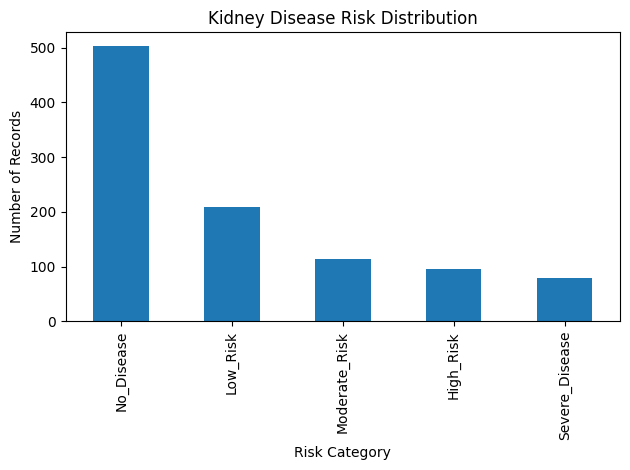

In [5]:
import matplotlib.pyplot as plt

df["Disease_Risk"].value_counts().plot(
    kind="bar",
    title="Kidney Disease Risk Distribution"
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [6]:

# Generate 500 additional records
np.random.seed(100)

n_new = 500

new_risk = np.random.choice(
    classes,
    size=n_new,
    p=[0.50, 0.20, 0.12, 0.10, 0.08]
)

new_level = pd.Series(new_risk).map({
    "No_Disease": 0,
    "Low_Risk": 1,
    "Moderate_Risk": 2,
    "High_Risk": 3,
    "Severe_Disease": 4
}).values

new_df = pd.DataFrame({
    "Age": np.random.randint(18, 85, n_new),
    "Blood_Pressure": np.random.normal(
        115 + new_level * 8, 12, n_new
    ).round(2),
    "Blood_Glucose": np.random.normal(
        90 + new_level * 25, 15, n_new
    ).round(2),
    "Creatinine": np.random.normal(
        0.8 + new_level * 0.7, 0.3, n_new
    ).round(2),
    "Hemoglobin": np.random.normal(
        15 - new_level * 1.5, 1.5, n_new
    ).round(2),
    "BMI": np.random.normal(
        24 + new_level * 1.5, 4, n_new
    ).round(2),
    "Urea": np.random.normal(
        25 + new_level * 15, 8, n_new
    ).round(2),
    "Sodium": np.random.normal(
        140 - new_level * 1.5, 3, n_new
    ).round(2),
    "Gender": np.random.choice(["Male", "Female"], n_new),
    "Smoking": np.random.choice(["Yes", "No"], n_new),
    "Diabetes": np.random.choice(["Yes", "No"], n_new),
    "Hypertension": np.random.choice(["Yes", "No"], n_new),
    "Disease_Risk": new_risk
})

# Combine old and new records
df_v2 = pd.concat([df, new_df], ignore_index=True)

# Introduce controlled missing values
for column in [
    "Blood_Pressure",
    "Blood_Glucose",
    "BMI",
    "Smoking"
]:
    df_v2.loc[
        df_v2.sample(frac=0.03, random_state=42).index,
        column
    ] = np.nan

# Save Version 2
df_v2.to_csv(
    "datasets/v2/kidney_disease_v2.csv",
    index=False
)

print("Version 2 dataset created successfully!")
print("Dataset Shape:", df_v2.shape)
print("Total Missing Values:", df_v2.isnull().sum().sum())


Version 2 dataset created successfully!
Dataset Shape: (1500, 13)
Total Missing Values: 180


In [7]:

import json
import hashlib
from datetime import datetime

def create_metadata(file_path, version, description):

    data = pd.read_csv(file_path)

    # Generate SHA-256 checksum
    with open(file_path, "rb") as f:
        checksum = hashlib.sha256(f.read()).hexdigest()

    metadata = {
        "version": version,
        "dataset_name": "Kidney Disease Risk Prediction",
        "description": description,
        "rows": int(data.shape[0]),
        "columns": int(data.shape[1]),
        "features": list(data.columns),
        "missing_values": int(data.isnull().sum().sum()),
        "target": "Disease_Risk",
        "file": file_path,
        "checksum": checksum,
        "created_at": datetime.now().isoformat()
    }

    output = f"metadata/{version}_metadata.json"

    with open(output, "w") as f:
        json.dump(metadata, f, indent=4)

    print(version, "metadata saved successfully!")

# Create metadata
create_metadata(
    "datasets/v1/kidney_disease_v1.csv",
    "v1",
    "Initial dataset containing 1000 records."
)

create_metadata(
    "datasets/v2/kidney_disease_v2.csv",
    "v2",
    "Added 500 records and introduced controlled missing values."
)


v1 metadata saved successfully!
v2 metadata saved successfully!


In [8]:
print("VERSION 1")
print("Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())

print("\nVERSION 2")
print("Shape:", df_v2.shape)
print("Missing Values:", df_v2.isnull().sum().sum())

print("\nDATASET VERSION COMPARISON")

comparison = pd.DataFrame({
    "Version": ["V1", "V2"],
    "Records": [len(df), len(df_v2)],
    "Features": [df.shape[1], df_v2.shape[1]],
    "Missing Values": [
        df.isnull().sum().sum(),
        df_v2.isnull().sum().sum()
    ]
})

print(comparison)

VERSION 1
Shape: (1000, 13)
Missing Values: 0

VERSION 2
Shape: (1500, 13)
Missing Values: 180

DATASET VERSION COMPARISON
  Version  Records  Features  Missing Values
0      V1     1000        13               0
1      V2     1500        13             180


In [9]:
def verify_dataset(metadata_path):

    with open(metadata_path, "r") as f:
        metadata = json.load(f)

    with open(metadata["file"], "rb") as f:
        current_hash = hashlib.sha256(f.read()).hexdigest()

    if current_hash == metadata["checksum"]:
        print(metadata["version"], "Integrity Verified")
    else:
        print(metadata["version"], "Dataset Modified!")

verify_dataset("metadata/v1_metadata.json")
verify_dataset("metadata/v2_metadata.json")

v1 Integrity Verified
v2 Integrity Verified


In [10]:
from getpass import getpass
import os

token = getpass("Enter GitHub Personal Access Token: ")

os.environ["GH_TOKEN"] = token

print("GitHub token received successfully!")

Enter GitHub Personal Access Token: ··········
GitHub token received successfully!


In [14]:

import pandas as pd
import numpy as np
import os
import json
import hashlib
from datetime import datetime

# Create project directories
for folder in [
    "datasets/v1",
    "datasets/v2",
    "metadata",
    "screenshots"
]:
    os.makedirs(folder, exist_ok=True)

classes = [
    "No_Disease",
    "Low_Risk",
    "Moderate_Risk",
    "High_Risk",
    "Severe_Disease"
]

probabilities = [0.50, 0.20, 0.12, 0.10, 0.08]

def generate_data(n, seed):
    np.random.seed(seed)

    risk = np.random.choice(
        classes, n, p=probabilities
    )

    level = pd.Series(risk).map({
        "No_Disease": 0,
        "Low_Risk": 1,
        "Moderate_Risk": 2,
        "High_Risk": 3,
        "Severe_Disease": 4
    }).values

    data = pd.DataFrame({
        "Age": np.random.randint(18, 85, n),
        "Blood_Pressure": np.random.normal(
            115 + level * 8, 12, n
        ).round(2),
        "Blood_Glucose": np.random.normal(
            90 + level * 25, 15, n
        ).round(2),
        "Creatinine": np.random.normal(
            0.8 + level * 0.7, 0.3, n
        ).round(2),
        "Hemoglobin": np.random.normal(
            15 - level * 1.5, 1.5, n
        ).round(2),
        "BMI": np.random.normal(
            24 + level * 1.5, 4, n
        ).round(2),
        "Urea": np.random.normal(
            25 + level * 15, 8, n
        ).round(2),
        "Sodium": np.random.normal(
            140 - level * 1.5, 3, n
        ).round(2),
        "Gender": np.random.choice(
            ["Male", "Female"], n
        ),
        "Smoking": np.random.choice(
            ["Yes", "No"], n
        ),
        "Diabetes": np.random.choice(
            ["Yes", "No"], n
        ),
        "Hypertension": np.random.choice(
            ["Yes", "No"], n
        ),
        "Disease_Risk": risk
    })

    return data


# Version 1: 1000 records
df_v1 = generate_data(1000, 42)

df_v1.to_csv(
    "datasets/v1/kidney_disease_v1.csv",
    index=False
)

# Version 2: 1500 records
df_v2 = generate_data(1500, 100)

# Introduce controlled missing values
for column in [
    "Blood_Pressure",
    "Blood_Glucose",
    "BMI",
    "Smoking"
]:
    missing_indices = df_v2.sample(
        frac=0.03,
        random_state=42
    ).index

    df_v2.loc[missing_indices, column] = np.nan

df_v2.to_csv(
    "datasets/v2/kidney_disease_v2.csv",
    index=False
)


# Generate dataset metadata
def create_metadata(data, version, file_path, description):

    with open(file_path, "rb") as f:
        checksum = hashlib.sha256(f.read()).hexdigest()

    metadata = {
        "version": version,
        "dataset_name": "Kidney Disease Risk Prediction",
        "description": description,
        "rows": len(data),
        "columns": len(data.columns),
        "features": list(data.columns),
        "missing_values": int(
            data.isnull().sum().sum()
        ),
        "target": "Disease_Risk",
        "file": file_path,
        "checksum": checksum,
        "created_at": datetime.now().isoformat()
    }

    with open(
        f"metadata/{version}_metadata.json", "w"
    ) as f:
        json.dump(metadata, f, indent=4)


create_metadata(
    df_v1,
    "v1",
    "datasets/v1/kidney_disease_v1.csv",
    "Initial dataset with 1000 records."
)

create_metadata(
    df_v2,
    "v2",
    "datasets/v2/kidney_disease_v2.csv",
    "1500 records with controlled missing values."
)


# Verify dataset integrity
def verify_dataset(version):

    path = f"datasets/{version}/kidney_disease_{version}.csv"

    with open(path, "rb") as f:
        current_hash = hashlib.sha256(f.read()).hexdigest()

    with open(
        f"metadata/{version}_metadata.json"
    ) as f:
        metadata = json.load(f)

    return current_hash == metadata["checksum"]


print("Experiment 1 completed successfully!")
print("V1 Shape:", df_v1.shape)
print("V2 Shape:", df_v2.shape)

print(
    "V1 Integrity:",
    "Verified" if verify_dataset("v1") else "Failed"
)

print(
    "V2 Integrity:",
    "Verified" if verify_dataset("v2") else "Failed"
)


Experiment 1 completed successfully!
V1 Shape: (1000, 13)
V2 Shape: (1500, 13)
V1 Integrity: Verified
V2 Integrity: Verified


In [15]:
%%writefile generate_dataset.py
# Copy the complete Python program from above here

Writing generate_dataset.py


In [16]:
import shutil
import os

# Create the scripts directory if it does not exist
os.makedirs("scripts", exist_ok=True)

shutil.move(
    "generate_dataset.py",
    "scripts/generate_dataset.py"
)

print("Python source file saved successfully!")

Python source file saved successfully!


In [17]:
from getpass import getpass
import os

os.environ["GH_TOKEN"] = getpass("Enter your NEW GitHub PAT: ")

print("Token received successfully!")

Enter your NEW GitHub PAT: ··········
Token received successfully!


In [18]:
import os
import subprocess
import tempfile

askpass = tempfile.NamedTemporaryFile(
    mode="w", delete=False
)

askpass.write("""#!/bin/sh
case "$1" in
  *Username*) echo "MrX9955" ;;
  *Password*) echo "$GH_TOKEN" ;;
  *) echo "" ;;
esac
""")

askpass.close()
os.chmod(askpass.name, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = askpass.name
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    # Capturing stderr to see the precise error message from Git
    result = subprocess.run(
        ["git", "push", "origin", "main"],
        env=env,
        capture_output=True,
        text=True
    )
    if result.returncode == 0:
        print("Successfully uploaded to GitHub!")
    else:
        print("Git Push Failed!")
        print("STDOUT:", result.stdout)
        print("STDERR:", result.stderr)

finally:
    os.remove(askpass.name)
    os.environ.pop("GH_TOKEN", None)

Git Push Failed!
STDOUT: 
STDERR: fatal: not a git repository (or any of the parent directories): .git



In [19]:
import os

print("Current directory:", os.getcwd())
print("Git repository exists:", os.path.exists(".git"))
print("Available files:", os.listdir())

Current directory: /content
Git repository exists: False
Available files: ['.config', 'screenshots', 'datasets', 'scripts', 'metadata', 'sample_data']


In [20]:
%cd /content

!git init
!git branch -M main

!git config --global user.name "MrX9955"
!git config --global user.email "YOUR_GITHUB_EMAIL"

print("Git initialized successfully!")

/content
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/.git/
Git initialized successfully!


In [21]:
!git remote add origin https://github.com/MrX9955/Kidney-Disease-MLOps.git

!git remote -v

origin	https://github.com/MrX9955/Kidney-Disease-MLOps.git (fetch)
origin	https://github.com/MrX9955/Kidney-Disease-MLOps.git (push)


In [22]:
!git add datasets metadata scripts screenshots

In [23]:
!git status

On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   datasets/v1/kidney_disease_v1.csv
	new file:   datasets/v2/kidney_disease_v2.csv
	new file:   metadata/v1_metadata.json
	new file:   metadata/v2_metadata.json
	new file:   scripts/generate_dataset.py

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.config/
	sample_data/



In [24]:
%%writefile .gitignore
.config/
sample_data/
__pycache__/
*.pyc
.env
.ipynb_checkpoints/

Writing .gitignore


In [25]:
!git add .gitignore
!git commit -m "Experiment 1: Dataset Creation and Version Management"

[main (root-commit) 7578e45] Experiment 1: Dataset Creation and Version Management
 6 files changed, 2563 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 datasets/v1/kidney_disease_v1.csv
 create mode 100644 datasets/v2/kidney_disease_v2.csv
 create mode 100644 metadata/v1_metadata.json
 create mode 100644 metadata/v2_metadata.json
 create mode 100644 scripts/generate_dataset.py


In [26]:
from getpass import getpass
import os

os.environ["GH_TOKEN"] = getpass("Enter GitHub PAT: ")

Enter GitHub PAT: ··········


In [27]:
import subprocess
import tempfile
import os

f = tempfile.NamedTemporaryFile(mode="w", delete=False)

f.write("""#!/bin/sh
if [ "$1" = "Username" ]; then
    echo "MrX9955"
else
    echo "$GH_TOKEN"
fi
""")

f.close()
os.chmod(f.name, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = f.name
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    result = subprocess.run(
        ["git", "push", "-u", "origin", "main"],
        env=env,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("GitHub upload successful!")

finally:
    os.remove(f.name)
    os.environ.pop("GH_TOKEN", None)


To https://github.com/MrX9955/Kidney-Disease-MLOps.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/MrX9955/Kidney-Disease-MLOps.git'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.



In [28]:
!git pull origin main --allow-unrelated-histories --no-rebase

remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 42 (delta 10), reused 35 (delta 7), pack-reused 0 (from 0)
Unpacking objects: 100% (42/42), 8.45 MiB | 4.13 MiB/s, done.
From https://github.com/MrX9955/Kidney-Disease-MLOps
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> origin/main
Auto-merging datasets/v2/kidney_disease_v2.csv
CONFLICT (add/add): Merge conflict in datasets/v2/kidney_disease_v2.csv
Auto-merging metadata/v1_metadata.json
CONFLICT (add/add): Merge conflict in metadata/v1_metadata.json
Auto-merging metadata/v2_metadata.json
CONFLICT (add/add): Merge conflict in metadata/v2_metadata.json
Automatic merge failed; fix conflicts and then commit the result.


In [29]:
!git checkout --ours -- datasets/v2/kidney_disease_v2.csv
!git checkout --ours -- metadata/v1_metadata.json
!git checkout --ours -- metadata/v2_metadata.json

print("Merge conflicts resolved using local dataset versions!")

Merge conflicts resolved using local dataset versions!


In [30]:
import json
import hashlib

for version in ["v1", "v2"]:
    with open(f"metadata/{version}_metadata.json") as f:
        metadata = json.load(f)

    with open(metadata["file"], "rb") as f:
        checksum = hashlib.sha256(f.read()).hexdigest()

    print(
        version,
        "Verified" if checksum == metadata["checksum"] else "Mismatch"
    )

v1 Verified
v2 Verified


In [31]:
!git status

On branch main
You have unmerged paths.
  (fix conflicts and run "git commit")
  (use "git merge --abort" to abort the merge)

Changes to be committed:
	new file:   .config/.last_opt_in_prompt.yaml
	new file:   .config/.last_survey_prompt.yaml
	new file:   .config/.last_update_check.json
	new file:   .config/active_config
	new file:   .config/config_sentinel
	new file:   .config/configurations/config_default
	new file:   .config/default_configs.db
	new file:   .config/gce
	new file:   .config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
	new file:   .config/logs/2026.10.26/22.18.15.518759.log
	new file:   .config/logs/2026.10.26/22.18.38.571729.log
	new file:   .config/logs/2026.10.26/22.18.44.768076.log
	new file:   .config/logs/2026.10.26/22.18.45.880512.log
	new file:   .config/logs/2026.10.26/22.18.52.867204.log
	new file:   .config/logs/2026.10.26/22.18.53.588181.log
	new file:   README.md
	new file:   sample_data/README.md
	new file:   sample_data/anscombe.json


In [32]:
!git rm -r --cached --ignore-unmatch .config sample_data

rm '.config/.last_opt_in_prompt.yaml'
rm '.config/.last_survey_prompt.yaml'
rm '.config/.last_update_check.json'
rm '.config/active_config'
rm '.config/config_sentinel'
rm '.config/configurations/config_default'
rm '.config/default_configs.db'
rm '.config/gce'
rm '.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db'
rm '.config/logs/2026.10.26/22.18.15.518759.log'
rm '.config/logs/2026.10.26/22.18.38.571729.log'
rm '.config/logs/2026.10.26/22.18.44.768076.log'
rm '.config/logs/2026.10.26/22.18.45.880512.log'
rm '.config/logs/2026.10.26/22.18.52.867204.log'
rm '.config/logs/2026.10.26/22.18.53.588181.log'
rm 'sample_data/README.md'
rm 'sample_data/anscombe.json'
rm 'sample_data/california_housing_test.csv'
rm 'sample_data/california_housing_train.csv'
rm 'sample_data/mnist_test.csv'
rm 'sample_data/mnist_train_small.csv'


In [33]:
%%writefile .gitignore
.config/
sample_data/
__pycache__/
*.pyc
.env
.ipynb_checkpoints/

Overwriting .gitignore


In [34]:
!git checkout --ours -- datasets/v2/kidney_disease_v2.csv
!git checkout --ours -- metadata/v1_metadata.json
!git checkout --ours -- metadata/v2_metadata.json

In [35]:
!git add datasets/v2/kidney_disease_v2.csv
!git add metadata/v1_metadata.json
!git add metadata/v2_metadata.json
!git add .gitignore

In [36]:
!git status

On branch main
All conflicts fixed but you are still merging.
  (use "git commit" to conclude merge)

Changes to be committed:
	new file:   README.md



In [37]:
import json
import hashlib

for version in ["v1", "v2"]:
    with open(f"metadata/{version}_metadata.json") as f:
        metadata = json.load(f)

    with open(metadata["file"], "rb") as f:
        current_hash = hashlib.sha256(f.read()).hexdigest()

    print(version, "Verified" if current_hash == metadata["checksum"] else "Mismatch")

v1 Verified
v2 Verified


In [38]:
!git status

On branch main
All conflicts fixed but you are still merging.
  (use "git commit" to conclude merge)

Changes to be committed:
	new file:   README.md



In [39]:
!git commit -m "Complete Experiment 1 repository merge"

[main 0cfb31a] Complete Experiment 1 repository merge


In [40]:
from getpass import getpass
import os

os.environ["GH_TOKEN"] = getpass("Enter GitHub PAT: ")

Enter GitHub PAT: ··········


In [41]:
import subprocess
import tempfile
import os

f = tempfile.NamedTemporaryFile(mode="w", delete=False)

f.write("""#!/bin/sh
if [ "$1" = "Username" ]; then
    echo "MrX9955"
else
    echo "$GH_TOKEN"
fi
""")

f.close()
os.chmod(f.name, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = f.name
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    result = subprocess.run(
        ["git", "push", "origin", "main"],
        env=env,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("GitHub upload successful!")

finally:
    os.remove(f.name)
    os.environ.pop("GH_TOKEN", None)


remote: fatal error in commit_refs_rules        
To https://github.com/MrX9955/Kidney-Disease-MLOps.git
 ! [remote rejected] main -> main (fatal error in commit_refs_rules
)
error: failed to push some refs to 'https://github.com/MrX9955/Kidney-Disease-MLOps.git'



In [42]:
!git status
!git log --oneline -5
!git remote -vc

On branch main
nothing to commit, working tree clean
0cfb31a (HEAD -> main) Complete Experiment 1 repository merge
7578e45 Experiment 1: Dataset Creation and Version Management
c9afded (origin/main) Remove next experiment section from README
5cdbedc Create README.md for Kidney Disease Risk Prediction
e735631 Experiment 1: Synthetic Dataset Creation and Version Management
error: unknown switch `c'
usage: git remote [-v | --verbose]
   or: git remote add [-t <branch>] [-m <master>] [-f] [--tags | --no-tags] [--mirror=<fetch|push>] <name> <url>
   or: git remote rename [--[no-]progress] <old> <new>
   or: git remote remove <name>
   or: git remote set-head <name> (-a | --auto | -d | --delete | <branch>)
   or: git remote [-v | --verbose] show [-n] <name>
   or: git remote prune [-n | --dry-run] <name>
   or: git remote [-v | --verbose] update [-p | --prune] [(<group> | <remote>)...]
   or: git remote set-branches [--add] <name> <branch>...
   or: git remote get-url [--push] [--all] <name>

In [43]:
!git remote -v

origin	https://github.com/MrX9955/Kidney-Disease-MLOps.git (fetch)
origin	https://github.com/MrX9955/Kidney-Disease-MLOps.git (push)


In [44]:
!git switch -c experiment-1-upload

Switched to a new branch 'experiment-1-upload'


In [45]:
from getpass import getpass
import os

os.environ["GH_TOKEN"] = getpass("Enter GitHub PAT: ")

Enter GitHub PAT: ··········


In [46]:
import subprocess
import tempfile
import os

f = tempfile.NamedTemporaryFile(mode="w", delete=False)

f.write("""#!/bin/sh
if [ "$1" = "Username" ]; then
    echo "MrX9955"
else
    echo "$GH_TOKEN"
fi
""")

f.close()
os.chmod(f.name, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = f.name
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    result = subprocess.run(
        ["git", "push", "-u", "origin", "experiment-1-upload"],
        env=env,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("Branch uploaded successfully!")

finally:
    os.remove(f.name)
    os.environ.pop("GH_TOKEN", None)

branch 'experiment-1-upload' set up to track 'origin/experiment-1-upload'.

remote: 
remote: Create a pull request for 'experiment-1-upload' on GitHub by visiting:        
remote:      https://github.com/MrX9955/Kidney-Disease-MLOps/pull/new/experiment-1-upload        
remote: 
To https://github.com/MrX9955/Kidney-Disease-MLOps.git
 * [new branch]      experiment-1-upload -> experiment-1-upload

Branch uploaded successfully!
